# 02 — Estimation Error

How noisy is a measured Sharpe ratio, and how fast does the noise shrink with the
track-record length `T`? Three views:

1. the sampling distribution of the realized SR vs horizon,
2. Lo's (2002) standard error against Monte Carlo,
3. the `t = SR·√T` rule and the **Minimum Track Record Length**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sharpe_illusion import simulation as sim
from sharpe_illusion import metrics, drawdown

PPY = sim.TRADING_DAYS_PER_YEAR
rng = np.random.default_rng(20260702)

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, AQUA, RED, MUTED = "#2a78d6", "#1baf7a", "#e34948", "#898781"


## 1. The sampling distribution of the realized SR vs horizon

True SR = 0.5, horizons of 1, 4, 16 years: the error halves only every quadrupling.

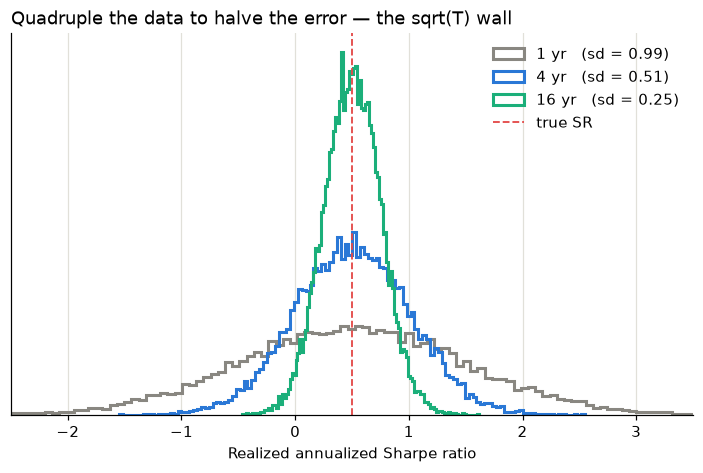

In [2]:
sr_true = 0.5
fig, ax = plt.subplots()
for years, color in [(1, MUTED), (4, BLUE), (16, AQUA)]:
    srs = sim.realized_sharpe(
        sim.simulate_returns(sr_true, PPY * years, 20_000, rng=rng))
    ax.hist(srs, bins=120, density=True, histtype="step", lw=2, color=color,
            label=f"{years} yr   (sd = {srs.std():.2f})")
ax.axvline(sr_true, color=RED, ls="--", lw=1.2, label="true SR")
ax.legend(frameon=False)
ax.set_xlabel("Realized annualized Sharpe ratio")
ax.set_yticks([]); ax.set_xlim(-2.5, 3.5)
ax.set_title("Quadruple the data to halve the error — the sqrt(T) wall", loc="left")
plt.show()

## 2. Lo (2002): the standard error formula vs Monte Carlo

`SE(SR) ≈ sqrt((1 + SR²/2)/n)` per period (IID case). Check it against simulation
across horizons — and annualize both sides.

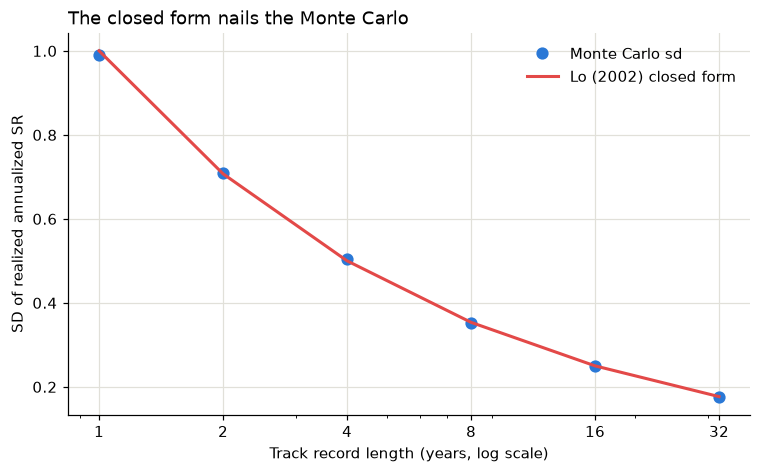

In [3]:
years_grid = np.array([1, 2, 4, 8, 16, 32])
mc_sd, theory_sd = [], []
for y in years_grid:
    n = PPY * y
    srs = sim.realized_sharpe(sim.simulate_returns(sr_true, n, 8000, rng=rng))
    mc_sd.append(srs.std())
    sr_pp = sr_true / np.sqrt(PPY)
    theory_sd.append(np.sqrt((1 + 0.5 * sr_pp**2) / n) * np.sqrt(PPY))

fig, ax = plt.subplots()
ax.plot(years_grid, mc_sd, "o", color=BLUE, ms=7, label="Monte Carlo sd")
ax.plot(years_grid, theory_sd, color=RED, lw=2, label="Lo (2002) closed form")
ax.set_xscale("log"); ax.set_xticks(years_grid); ax.set_xticklabels(years_grid)
ax.legend(frameon=False)
ax.set_xlabel("Track record length (years, log scale)")
ax.set_ylabel("SD of realized annualized SR")
ax.set_title("The closed form nails the Monte Carlo", loc="left")
plt.show()

## 3. `t = SR·√T` and the Minimum Track Record Length

The t-statistic of the mean return is the annualized SR times the square root of the
track length in years. Setting `t = 2` (≈97.5% one-sided confidence) and solving for
`T` gives the naive answer; Bailey & López de Prado's **MinTRL** is the same idea done
properly on the per-period SR (and generalizes to non-normal returns).

In [4]:
print(f"{'true SR':>8} | {'naive (2/SR)^2':>15} | {'MinTRL (95%)':>13} | {'MinTRL (97.5%)':>15}")
print("-" * 62)
for sr in [0.25, 0.5, 1.0, 2.0]:
    sr_pp = sr / np.sqrt(PPY)
    naive = (2 / sr) ** 2
    t95  = metrics.minimum_track_record_length(sr_pp, confidence=0.95)  / PPY
    t975 = metrics.minimum_track_record_length(sr_pp, confidence=0.975) / PPY
    print(f"{sr:>8.2f} | {naive:>13.1f} y | {t95:>11.1f} y | {t975:>13.1f} y")

 true SR |  naive (2/SR)^2 |  MinTRL (95%) |  MinTRL (97.5%)
--------------------------------------------------------------
    0.25 |          64.0 y |        43.3 y |          61.5 y
    0.50 |          16.0 y |        10.8 y |          15.4 y
    1.00 |           4.0 y |         2.7 y |           3.9 y
    2.00 |           1.0 y |         0.7 y |           1.0 y


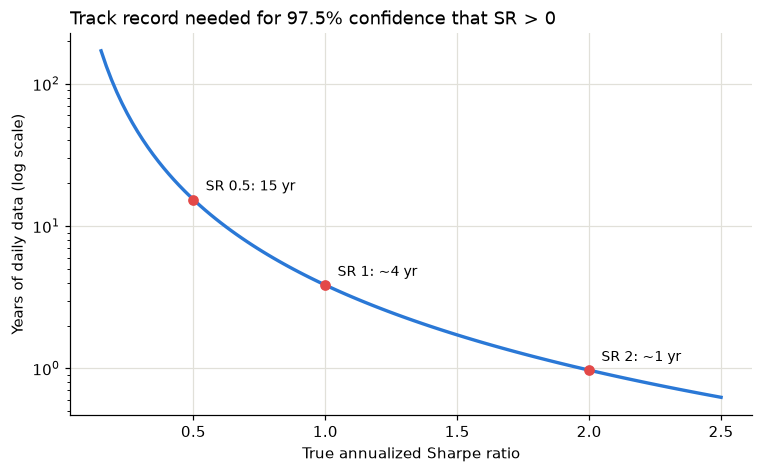

In [5]:
# The same fact as a picture: years needed vs true SR (97.5% confidence)
sr_grid = np.linspace(0.15, 2.5, 120)
yrs = [metrics.minimum_track_record_length(s / np.sqrt(PPY), confidence=0.975) / PPY
       for s in sr_grid]
fig, ax = plt.subplots()
ax.plot(sr_grid, yrs, color=BLUE, lw=2.2)
ax.set_yscale("log")
for s, lbl in [(0.5, "15 yr"), (1.0, "~4 yr"), (2.0, "~1 yr")]:
    y = metrics.minimum_track_record_length(s / np.sqrt(PPY), confidence=0.975) / PPY
    ax.plot([s], [y], "o", color=RED, ms=6)
    ax.annotate(f"SR {s:g}: {lbl}", (s, y), textcoords="offset points",
                xytext=(8, 6), fontsize=9)
ax.set_xlabel("True annualized Sharpe ratio")
ax.set_ylabel("Years of daily data (log scale)")
ax.set_title("Track record needed for 97.5% confidence that SR > 0", loc="left")
plt.show()

**Takeaway.** Below SR ≈ 1, required track records exceed the lifetime of most funds.
Any realized Sharpe you are shown is, almost always, a draw from a distribution wider
than the effect it claims to measure.

Next: [03_psr_dsr_mintrl](03_psr_dsr_mintrl.ipynb) — the corrections that make the
number honest.